In [ ]:
from google.colab import files
import zipfile
# Step 1: Upload zip file
uploaded = files.upload()

Saving dogcatds.zip to dogcatds.zip


In [ ]:
# Step 2: Unzip it
zip_path = "dogcatds.zip"  # Change to your uploaded filename
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [ ]:
# Import Libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

In [ ]:
# Paths & Parameters
TRAIN_DIR = 'dataset/train'
VAL_DIR   = 'dataset/validation'
IMG_SIZE  = (150, 150)
BATCH_SIZE = 32
EPOCHS = 15

In [ ]:
# Data Augmentation
# Training data generator with augmentation
train_datagen = ImageDataGenerator(
rescale=1./255,
rotation_range=25,
width_shift_range=0.1,
height_shift_range=0.1,
shear_range=0.1,
zoom_range=0.2,
horizontal_flip=True,
fill_mode='nearest' )

In [ ]:
# Update correct path based on structure discovered
TRAIN_DIR = 'dataset/dogcatds/training_set'

# Configure training data generator with a 20% validation split
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2  # Set aside 20% of the images for validation
)

# Validation data generator (only rescale, also with validation split)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Data generator for training subset
train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'  # Set as training data
)

# Data generator for validation subset
val_gen = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'  # Set as validation data
)

Found 1619 images belonging to 2 classes.
Found 404 images belonging to 2 classes.


In [ ]:
# Load VGG16 Base Model
# Load VGG16 without top layers, pretrained on ImageNet
base_model = VGG16(weights='imagenet', include_top=False,
                   input_shape=(150,150,3))
# Freeze base layers so pretrained weights are not updated
base_model.trainable = False

In [ ]:
# Build Classifier on Top
model = Sequential([
base_model,
Flatten(),
Dense(256, activation='relu'),
Dropout(0.5),
Dense(1, activation='sigmoid')
 ])

In [ ]:
# Compile model
model.compile(optimizer=Adam(learning_rate=1e-4),
loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# Train the Model
history = model.fit(
train_gen,
validation_data=val_gen,
epochs=EPOCHS,
steps_per_epoch=train_gen.samples // BATCH_SIZE,
validation_steps=val_gen.samples // BATCH_SIZE )

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 386ms/step - accuracy: 0.6862 - loss: 0.5827 - val_accuracy: 0.7396 - val_loss: 0.5310
Epoch 2/15
 1/50 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.7188 - loss: 0.5601

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7188 - loss: 0.5601 - val_accuracy: 0.7500 - val_loss: 0.5100
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 417ms/step - accuracy: 0.7984 - loss: 0.4277 - val_accuracy: 0.8021 - val_loss: 0.4238
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7812 - loss: 0.3830 - val_accuracy: 0.8073 - val_loss: 0.4186
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 407ms/step - accuracy: 0.8399 - loss: 0.3610 - val_accuracy: 0.8203 - val_loss: 0.3933
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8125 - loss: 0.4577 - val_accuracy: 0.8203 - val_loss: 0.4013
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 279ms/step - accuracy: 0.8349 - loss: 0.3604 - val_accuracy: 0.8099 - val_loss: 0.4166
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8125 - loss: 0.3608 - val_accuracy: 0.8099 - val_loss: 0.4181
Epoch 9/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 287ms/step - accuracy: 0.8589 - loss: 0.3251 - val_accuracy: 0.8359 - val_

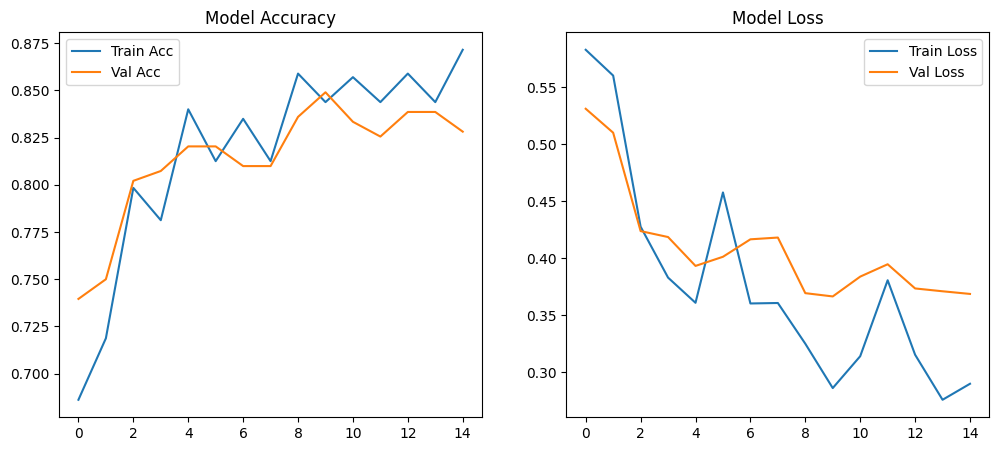

In [ ]:
# Plot Accuracy & Loss
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Model Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

In [ ]:
#Predict on New Images
import numpy as np
from tensorflow.keras.preprocessing import image

# Using an existing image path from the extracted dataset
img_path = 'dataset/dogcatds/training_set/cats/cat.4001.jpg'

# Load and preprocess the image
img = image.load_img(img_path, target_size=(150,150))
img_array = image.img_to_array(img)/255.0
img_array = np.expand_dims(img_array, axis=0)

In [ ]:
# Predict
pred = model.predict(img_array)[0][0]
label = 'Dog' if pred > 0.5 else 'Cat'
print(f'Prediction: {label} ({pred:.2f})')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Prediction: Cat (0.14)


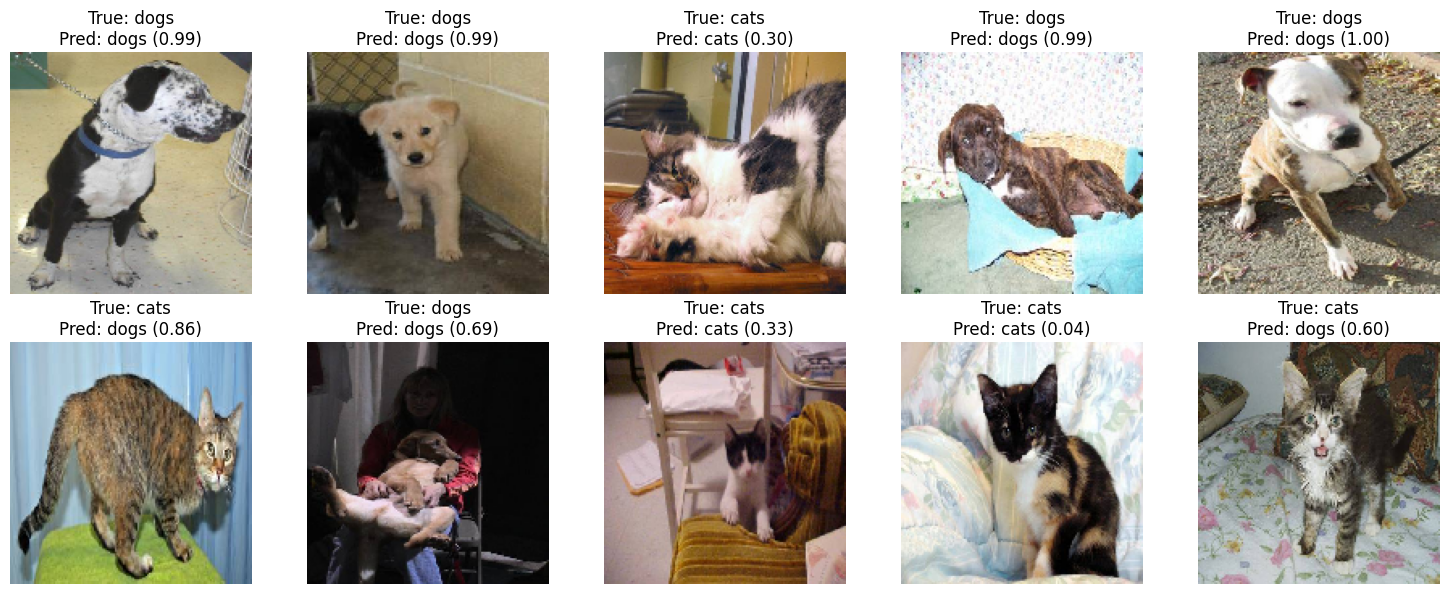

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Fetch a batch of validation images and labels
x_val_batch, y_val_batch = next(val_gen)

# Map indices back to class names
class_names = {v: k for k, v in val_gen.class_indices.items()}

num_images_to_show = min(10, len(x_val_batch))
subset_images = x_val_batch[:num_images_to_show]

# Run batch prediction in a single step to keep the output clean
pred_probs = model.predict(subset_images, verbose=0)

plt.figure(figsize=(15, 6))
for i in range(num_images_to_show):
    img = subset_images[i]
    true_label_idx = int(y_val_batch[i])

    # Extract prediction probability for this image
    pred_prob = pred_probs[i][0]
    pred_label_idx = 1 if pred_prob > 0.5 else 0

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"True: {class_names[true_label_idx]}\nPred: {class_names[pred_label_idx]} ({pred_prob:.2f})")

plt.tight_layout()
plt.show()

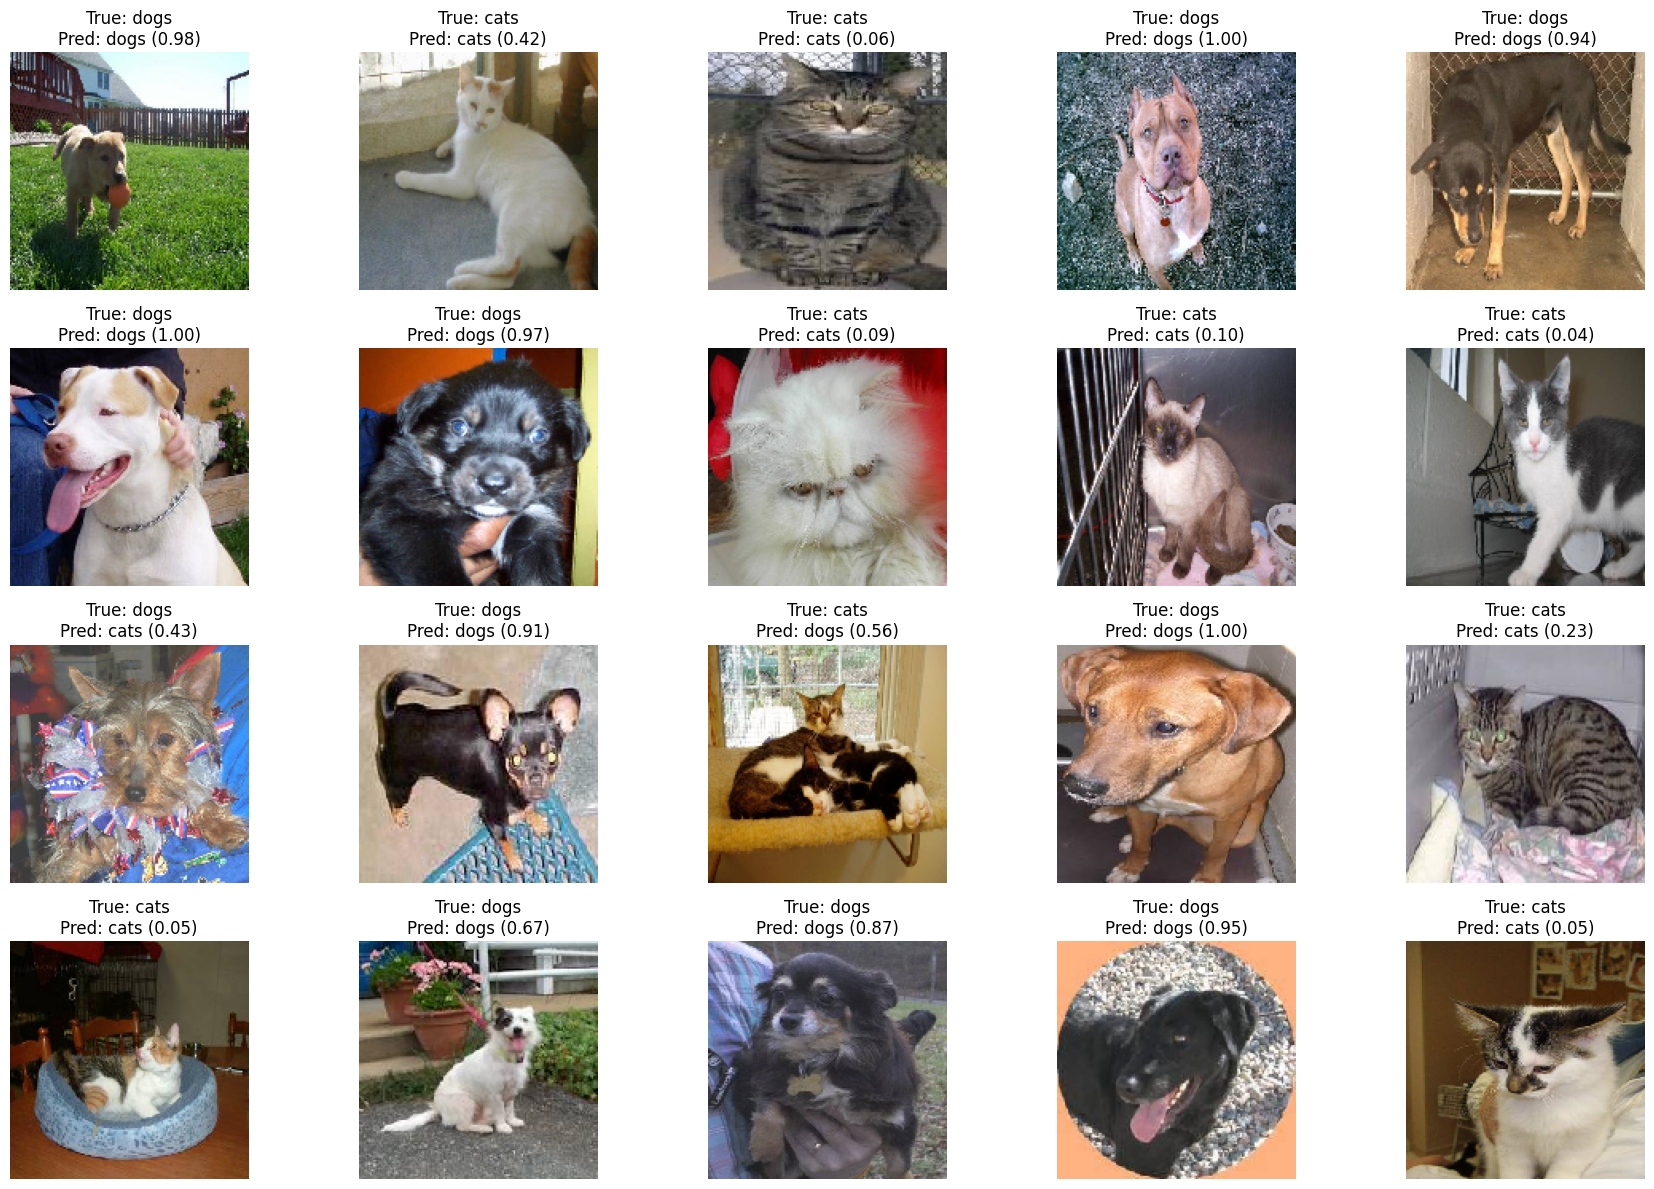

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x_val_batch, y_val_batch = next(val_gen)

class_names = {v: k for k, v in val_gen.class_indices.items()}

num_images_to_show = min(20, len(x_val_batch))
subset_images = x_val_batch[:num_images_to_show]


pred_probs = model.predict(subset_images, verbose=0)

plt.figure(figsize=(18, 12))

for i in range(num_images_to_show):
    img = subset_images[i]
    true_label_idx = int(y_val_batch[i])


    pred_prob = float(pred_probs[i][0])
    pred_label_idx = 1 if pred_prob > 0.5 else 0

    # Display image
    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.axis('off')

    plt.title(
        f"True: {class_names[true_label_idx]}\n"
        f"Pred: {class_names[pred_label_idx]} ({pred_prob:.2f})"
    )

plt.tight_layout()
plt.show()